In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
from google.colab.patches import cv2_imshow

TRAINED_MODEL_PATH = '/content/gdrive/MyDrive/Colab Notebooks/yolo26/best.pt'


In [4]:
!pip install -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.1 MB/s eta 0:00:00


In [5]:
from ultralytics import YOLO

model = YOLO(TRAINED_MODEL_PATH)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [10]:
IMG_URL = '/content/Safety_Helmet_Dataset/test/images/helmet-12-_jpg.rf.e060b7cfb30b033ca50fc1b9ed48efe7.jpg'

In [7]:
!unzip -q '/content/gdrive/MyDrive/Colab Notebooks/yolo26/Safety_Helmet_Dataset.zip' -d Safety_Helmet_Dataset

In [8]:
YAML_PATH = '/content/Safety_Helmet_Dataset/data.yaml'
IMG_SIZE = 640
model.val(imgsz=IMG_SIZE, data=YAML_PATH, split='test')

Ultralytics 8.4.108 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.4 ms, read: 522.7±237.7 MB/s, size: 26.1 KB)
val: Scanning /content/Safety_Helmet_Dataset/test/labels... 109 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 109/109 757.7it/s 0.1s
val: New cache created: /content/Safety_Helmet_Dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.9s/it 34.3s
                   all        109        320      0.832      0.791      0.863      0.452
                  head         12         16      0.923      0.745      0.872      0.423
                helmet         98        162      0.798      0.856      0.906      0.456
                person         78        142      0.774      0.771      0.812      0.476
Speed: 9.5ms preprocess, 290.5ms inference, 0.0ms loss,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7df662910620>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04


image 1/1 /content/Safety_Helmet_Dataset/test/images/helmet-12-_jpg.rf.e060b7cfb30b033ca50fc1b9ed48efe7.jpg: 640x640 2 helmets, 3 persons, 244.0ms
Speed: 9.0ms preprocess, 244.0ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)
Ultralytics 8.4.108 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 415.2±123.6 MB/s, size: 27.3 KB)
val: Scanning /content/Safety_Helmet_Dataset/valid/labels.cache... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 4.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 4.3s/it 1:00
                   all        218        586      0.866       0.82       0.89      0.461
                  head         18         27      0.906      0.716      0.841      0.402
                helmet        195        285      0.853      0.919      0.942      0.471
                person        155        274   

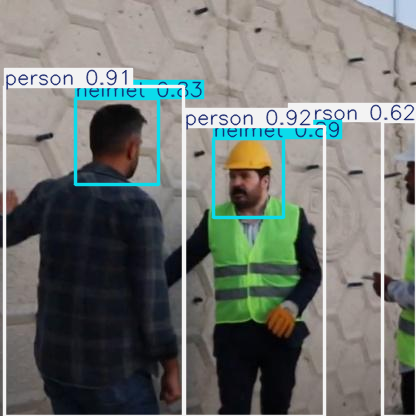

In [11]:
CONF_THRESHOLD = 0.3
results = model.predict(source=IMG_URL, conf=CONF_THRESHOLD, imgsz=640)
model.val()
annotated_image = results[0].plot()
cv2_imshow(annotated_image)

In [13]:
print(results[0].boxes)

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([2., 2., 1., 1., 2.])
conf: tensor([0.9185, 0.9141, 0.8854, 0.8334, 0.6197])
data: tensor([[184.4548, 126.0776, 324.9711, 416.0000,   0.9185,   2.0000],
        [  4.4048,  86.5107, 183.6766, 416.0000,   0.9141,   2.0000],
        [213.8915, 138.5249, 283.2812, 217.1852,   0.8854,   1.0000],
        [ 75.2698,  98.5628, 158.7269, 184.8485,   0.8334,   1.0000],
        [382.4985, 121.8200, 416.0000, 416.0000,   0.6197,   2.0000]])
id: None
is_track: False
orig_shape: (416, 416)
shape: torch.Size([5, 6])
xywh: tensor([[254.7130, 271.0388, 140.5163, 289.9224],
        [ 94.0407, 251.2554, 179.2718, 329.4893],
        [248.5863, 177.8551,  69.3897,  78.6603],
        [116.9983, 141.7056,  83.4571,  86.2857],
        [399.2493, 268.9100,  33.5015, 294.1800]])
xywhn: tensor([[0.6123, 0.6515, 0.3378, 0.6969],
        [0.2261, 0.6040, 0.4309, 0.7920],
        [0.5976, 0.4275, 0.1668, 0.1891],
        [0.2812, 0.3406, 0.2006,